# Exploratory Data Analysis — BirdCLEF+ 2026

Before building any models, I want to understand what the data looks like — how many species, how the classes are distributed, what the audio sounds like, etc.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import os
from pathlib import Path
from IPython.display import Audio

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

DATA_DIR = Path("../birdclef-2026")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 1. Load metadata

In [9]:
train = pd.read_csv(DATA_DIR / "train.csv")
taxonomy = pd.read_csv(DATA_DIR / "taxonomy.csv")
soundscape_labels = pd.read_csv(DATA_DIR / "train_soundscapes_labels.csv")

print("train.csv:", train.shape)
print("taxonomy.csv:", taxonomy.shape)
print("soundscape_labels:", soundscape_labels.shape)
print()
train.head(3)

train.csv: (35549, 15)
taxonomy.csv: (234, 5)
soundscape_labels: (1478, 4)



,primary_label,secondary_labels,type,latitude,longitude,scientific_name,common_name,class_name,inat_taxon_id,author,license,rating,url,filename,collection
0,1161364,[],[],-22.7562,-46.8666,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1216197....,1161364/iNat1216197.ogg,iNat
1,1161364,[],[],-22.7558,-46.8700,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1114648....,1161364/iNat1114648.ogg,iNat
2,1161364,[],[],-22.7547,-46.8728,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/810195.m...,1161364/iNat810195.ogg,iNat


In [10]:
print("Columns in train.csv:")
print(list(train.columns))
print()
print("Columns in taxonomy.csv:")
print(list(taxonomy.columns))
print()
print("Columns in soundscape_labels:")
print(list(soundscape_labels.columns))

Columns in train.csv:
['primary_label', 'secondary_labels', 'type', 'latitude', 'longitude', 'scientific_name', 'common_name', 'class_name', 'inat_taxon_id', 'author', 'license', 'rating', 'url', 'filename', 'collection']

Columns in taxonomy.csv:
['primary_label', 'inat_taxon_id', 'scientific_name', 'common_name', 'class_name']

Columns in soundscape_labels:
['filename', 'start', 'end', 'primary_label']


## 2. Class distribution

In [11]:
species_counts = train['primary_label'].value_counts()

print(f"Number of unique species in train_audio: {len(species_counts)}")
print(f"Number of target species (taxonomy): {len(taxonomy)}")
print(f"Total training recordings: {len(train)}")
print()
print(f"Max samples per species: {species_counts.max()} ({species_counts.idxmax()})")
print(f"Min samples per species: {species_counts.min()}")
print(f"Median samples per species: {species_counts.median():.0f}")
print()

# species with very few samples
rare = species_counts[species_counts < 10]
print(f"Species with < 10 samples: {len(rare)}")
print(rare.to_string())

Number of unique species in train_audio: 206
Number of target species (taxonomy): 234
Total training recordings: 35549

Max samples per species: 499 (rubthr1)
Min samples per species: 1
Median samples per species: 125

Species with < 10 samples: 25
primary_label
555145     9
22967      8
760266     7
22930      6
22961      6
22985      6
67252      6
1595929    5
23154      5
66971      5
738183     5
23176      4
25214      3
476521     3
555123     3
64898      3
74580      3
sptnig1    3
209233     2
24321      2
70711      2
116570     1
23150      1
23724      1
516975     1


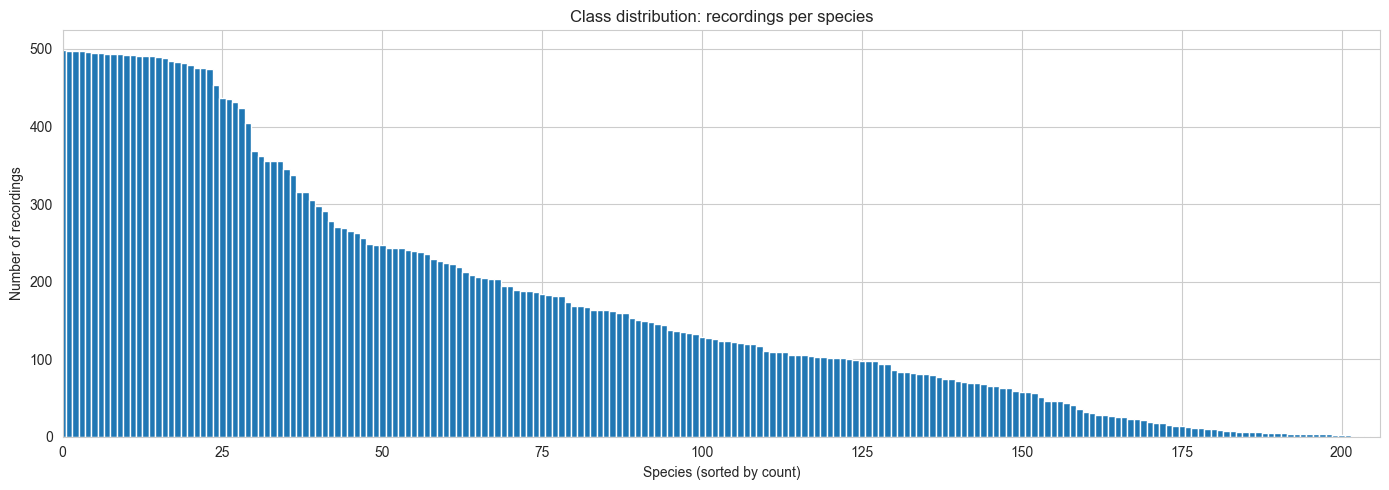

In [12]:
# samples per species histogram
fig, ax = plt.subplots(figsize=(14, 5))
species_counts_sorted = species_counts.sort_values(ascending=False)
ax.bar(range(len(species_counts_sorted)), species_counts_sorted.values, width=1.0)
ax.set_xlabel("Species (sorted by count)")
ax.set_ylabel("Number of recordings")
ax.set_title("Class distribution: recordings per species")
ax.set_xlim(0, len(species_counts_sorted))
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150)
plt.show()

## 3. Taxonomic groups

In [13]:
# how many species per taxonomic class
tax_counts = taxonomy['class_name'].value_counts()
print("Species per taxonomic class:")
print(tax_counts)
print()

# how many recordings per taxonomic class (train.csv already has class_name)
rec_per_class = train['class_name'].value_counts()
print("Recordings per taxonomic class:")
print(rec_per_class)

Species per taxonomic class:
class_name
Aves        162
Amphibia     35
Insecta      28
Mammalia      8
Reptilia      1
Name: count, dtype: int64

Recordings per taxonomic class:
class_name
Aves        34799
Amphibia      451
Insecta       199
Mammalia       99
Reptilia        1
Name: count, dtype: int64


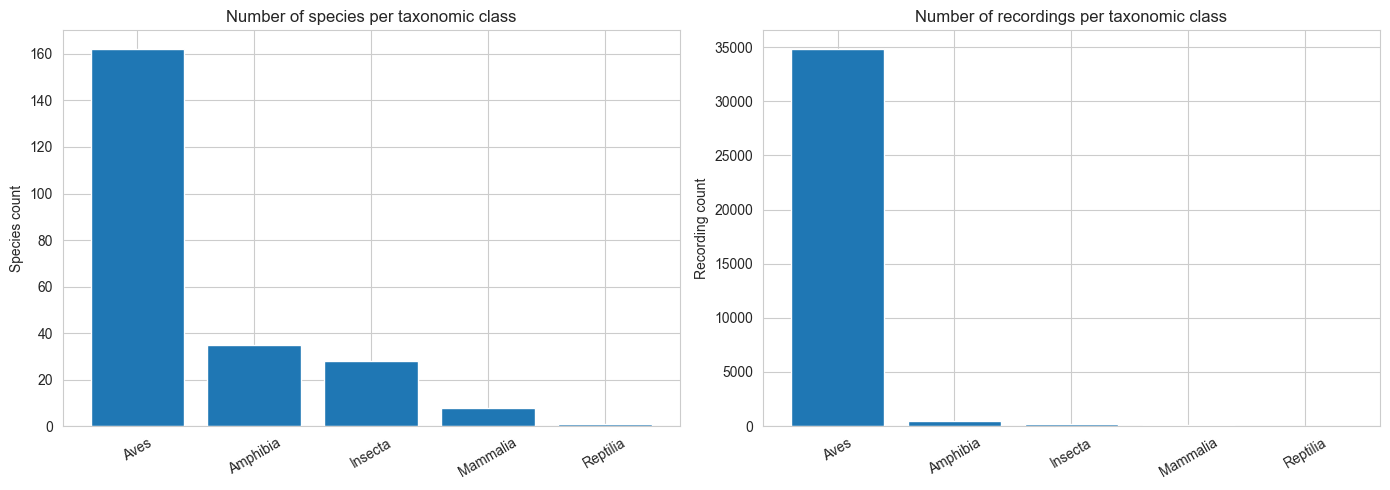

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(tax_counts.index, tax_counts.values)
axes[0].set_title("Number of species per taxonomic class")
axes[0].set_ylabel("Species count")

axes[1].bar(rec_per_class.index, rec_per_class.values)
axes[1].set_title("Number of recordings per taxonomic class")
axes[1].set_ylabel("Recording count")

for ax in axes:
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(FIG_DIR / "taxonomic_distribution.png", dpi=150)
plt.show()

## 4. Rating and collection distribution

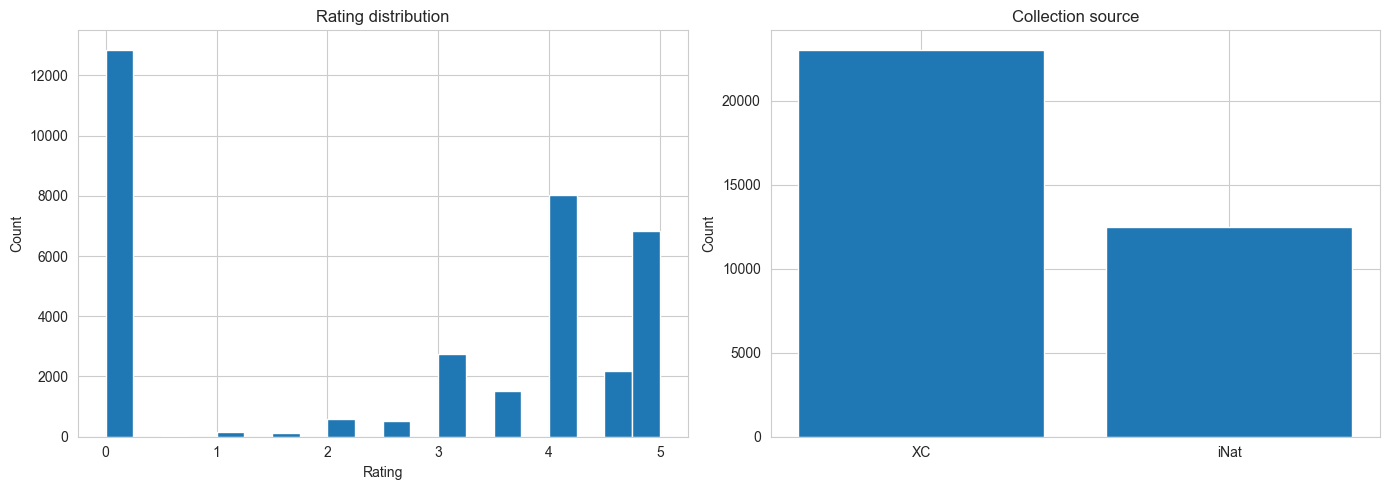


Rating stats:
count    35549.000000
mean         2.600748
std          2.070471
min          0.000000
25%          0.000000
50%          3.500000
75%          4.500000
max          5.000000
Name: rating, dtype: float64

Collection counts:
collection
XC      23043
iNat    12506
Name: count, dtype: int64


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# rating
train['rating'].hist(bins=20, ax=axes[0])
axes[0].set_title("Rating distribution")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

# collection
col_counts = train['collection'].value_counts()
axes[1].bar(col_counts.index, col_counts.values)
axes[1].set_title("Collection source")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig(FIG_DIR / "rating_collection.png", dpi=150)
plt.show()

print(f"\nRating stats:\n{train['rating'].describe()}")
print(f"\nCollection counts:\n{col_counts}")

## 5. Missing species check

I want to check if there are species in the target list (taxonomy) that don't have any training audio. If so, we won't be able to train on those at all.

In [16]:
target_species = set(taxonomy['primary_label'].astype(str))
train_species = set(train['primary_label'].astype(str))

missing = target_species - train_species
present = target_species & train_species

print(f"Target species: {len(target_species)}")
print(f"Species with training audio: {len(present)}")
print(f"Species WITHOUT training audio: {len(missing)}")

if missing:
    print("\nMissing species:")
    for s in sorted(missing):
        row = taxonomy[taxonomy['primary_label'].astype(str) == s]
        if len(row):
            print(f"  {s} — {row.iloc[0]['common_name']} ({row.iloc[0]['class_name']})")

Target species: 234
Species with training audio: 206
Species WITHOUT training audio: 28

Missing species:
  1491113 — Guaraní leaf-litter frog (Amphibia)
  25073 — Chiasmocleis mehelyi (Amphibia)
  47158son01 — Insect sonotype01 (Insecta)
  47158son02 — Insect sonotype02 (Insecta)
  47158son03 — Insect sonotype03 (Insecta)
  47158son04 — Insect sonotype04 (Insecta)
  47158son05 — Insect sonotype05 (Insecta)
  47158son06 — Insect sonotype06 (Insecta)
  47158son07 — Insect sonotype07 (Insecta)
  47158son08 — Insect sonotype08 (Insecta)
  47158son09 — Insect sonotype09 (Insecta)
  47158son10 — Insect sonotype10 (Insecta)
  47158son11 — Insect sonotype11 (Insecta)
  47158son12 — Insect sonotype12 (Insecta)
  47158son13 — Insect sonotype13 (Insecta)
  47158son14 — Insect sonotype14 (Insecta)
  47158son15 — Insect sonotype15 (Insecta)
  47158son16 — Insect sonotype16 (Insecta)
  47158son17 — Insect sonotype17 (Insecta)
  47158son18 — Insect sonotype18 (Insecta)
  47158son19 — Insect sonotype

## 6. Soundscape labels analysis

In [17]:
print(f"Total labeled segments: {len(soundscape_labels)}")
print(f"Unique soundscape files: {soundscape_labels['filename'].nunique()}")
print()

soundscape_labels.head()

Total labeled segments: 1478
Unique soundscape files: 66



,filename,start,end,primary_label
0,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:00,00:00:05,22961;23158;24321;517063;65380
1,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:05,00:00:10,22961;23158;24321;517063;65380
2,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:10,00:00:15,22961;23158;24321;517063;65380
3,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:15,00:00:20,22961;23158;24321;517063;65380
4,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:20,00:00:25,22961;23158;24321;517063;65380


Species per segment — min: 1, max: 10, mean: 4.2, median: 4


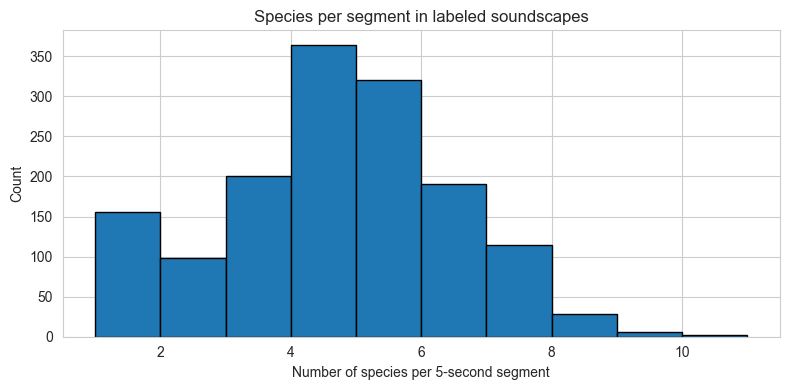

In [18]:
# labels are semicolon-separated
species_per_segment = soundscape_labels['primary_label'].str.split(';').apply(len)

print(f"Species per segment — min: {species_per_segment.min()}, max: {species_per_segment.max()}, "
      f"mean: {species_per_segment.mean():.1f}, median: {species_per_segment.median():.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
species_per_segment.hist(bins=range(1, species_per_segment.max() + 2), ax=ax, edgecolor='black')
ax.set_xlabel("Number of species per 5-second segment")
ax.set_ylabel("Count")
ax.set_title("Species per segment in labeled soundscapes")
plt.tight_layout()
plt.savefig(FIG_DIR / "species_per_segment.png", dpi=150)
plt.show()

In [19]:
# which species appear in soundscapes
all_soundscape_species = []
for labels in soundscape_labels['primary_label']:
    all_soundscape_species.extend(labels.split(';'))

soundscape_species_counts = pd.Series(all_soundscape_species).value_counts()
soundscape_species_set = set(all_soundscape_species)

print(f"Unique species in soundscape labels: {len(soundscape_species_set)}")

# species only in soundscapes, not in train_audio
only_in_soundscapes = soundscape_species_set - train_species
print(f"Species in soundscapes but NOT in train_audio: {len(only_in_soundscapes)}")
if only_in_soundscapes:
    for s in sorted(only_in_soundscapes):
        print(f"  {s}")

print(f"\nTop 15 species in soundscape labels:")
print(soundscape_species_counts.head(15).to_string())

Unique species in soundscape labels: 75
Species in soundscapes but NOT in train_audio: 28
  1491113
  25073
  47158son01
  47158son02
  47158son03
  47158son04
  47158son05
  47158son06
  47158son07
  47158son08
  47158son09
  47158son10
  47158son11
  47158son12
  47158son13
  47158son14
  47158son15
  47158son16
  47158son17
  47158son18
  47158son19
  47158son20
  47158son21
  47158son22
  47158son23
  47158son24
  47158son25
  517063

Top 15 species in soundscape labels:
65380         666
517063        626
22973         426
555146        420
23158         350
24279         346
24321         344
22967         310
66971         298
47158son25    168
1491113       158
chacha1       130
whtdov        126
47158son07     96
47158son17     86


## 7. Audio visualization

I picked one example from each taxonomic class to see what the audio actually looks like. Plotting both the waveform and the mel-spectrogram side by side.

In [20]:
# pick one example per taxonomic class
examples = {}
for cls in taxonomy['class_name'].unique():
    species_in_class = taxonomy[taxonomy['class_name'] == cls]['primary_label'].astype(str).values
    for sp in species_in_class:
        rows = train[train['primary_label'].astype(str) == sp]
        if len(rows) > 0:
            examples[cls] = rows.iloc[0]
            break

print("Selected examples:")
for cls, row in examples.items():
    print(f"  {cls}: {row['common_name']} — {row['filename']}")

Selected examples:
  Insecta: Guyalna cuta — 1161364/iNat1216197.ogg
  Reptilia: Southern Spectacled Caiman — 116570/iNat1460166.ogg
  Amphibia: Wrestler Frog — 1176823/iNat936019.ogg
  Mammalia: Feral Horse — 209233/iNat1545859.ogg
  Aves: Ashy-headed Greenlet — ashgre1/XC684562.ogg


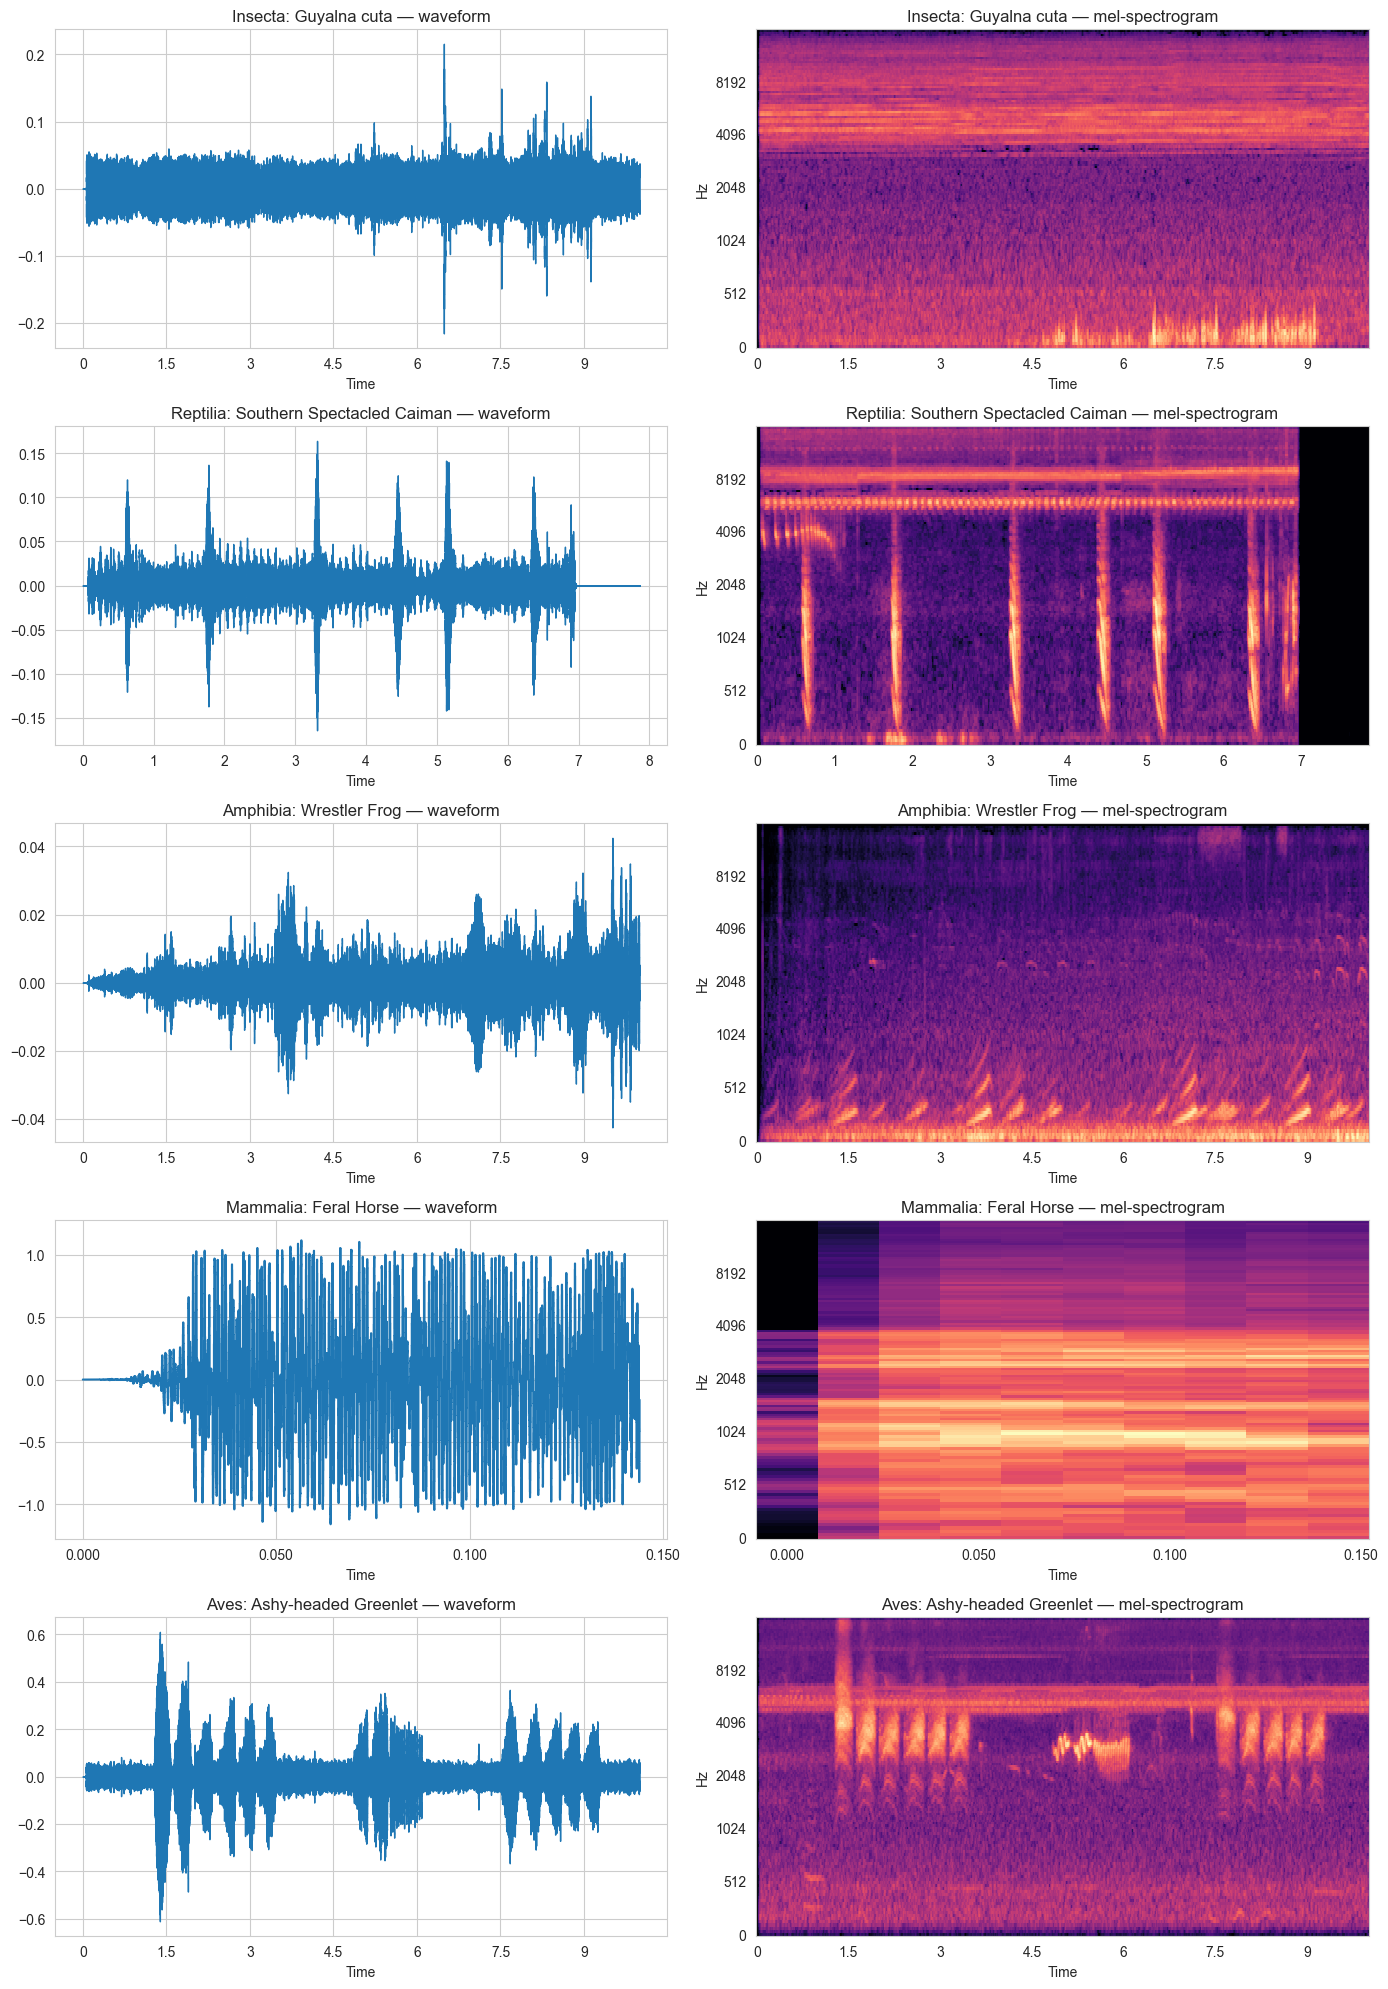

In [21]:
# plot waveform + mel-spectrogram for each example
fig, axes = plt.subplots(len(examples), 2, figsize=(14, 4 * len(examples)))

for i, (cls, row) in enumerate(examples.items()):
    path = DATA_DIR / "train_audio" / row['filename']
    y, sr = librosa.load(path, sr=32000, duration=10)
    
    # waveform
    librosa.display.waveshow(y, sr=sr, ax=axes[i, 0])
    axes[i, 0].set_title(f"{cls}: {row['common_name']} — waveform")
    
    # mel-spectrogram
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    S_db = librosa.power_to_db(S, ref=np.max)
    img = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[i, 1])
    axes[i, 1].set_title(f"{cls}: {row['common_name']} — mel-spectrogram")

plt.tight_layout()
plt.savefig(FIG_DIR / "audio_examples_per_class.png", dpi=150)
plt.show()

### Clean train_audio vs noisy soundscape

I wanted to see how different the training audio is from the soundscapes. The training clips are usually clean, close-up recordings, while soundscapes are noisy field recordings with multiple species at once.

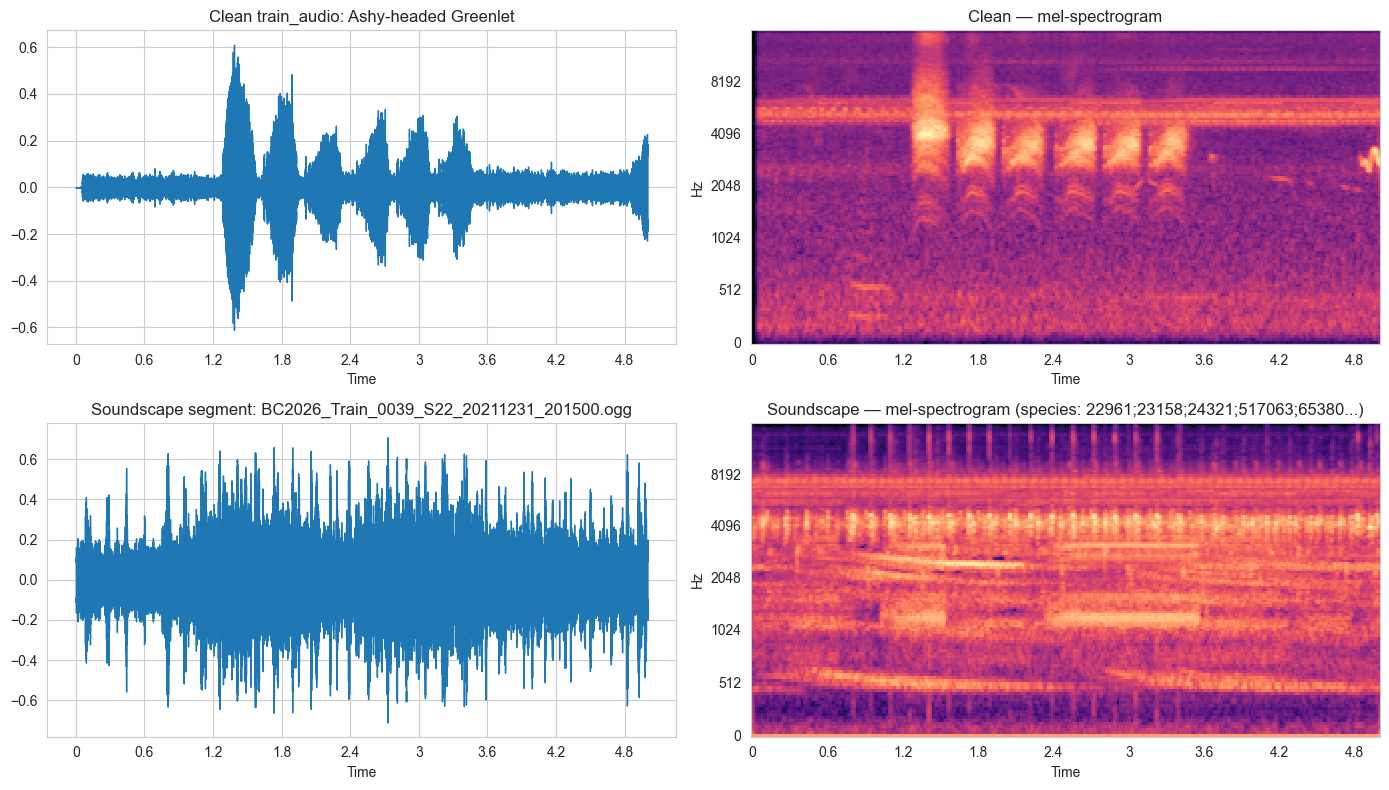

In [22]:
# pick a clean train_audio example (high rating bird)
birds = train[train['class_name'] == 'Aves'].sort_values('rating', ascending=False)
clean_example = birds.iloc[0]
clean_path = DATA_DIR / "train_audio" / clean_example['filename']

# pick a soundscape segment
sc_row = soundscape_labels.iloc[0]
sc_path = DATA_DIR / "train_soundscapes" / sc_row['filename']

# parse start time
start_parts = sc_row['start'].split(':')
start_sec = int(start_parts[0]) * 3600 + int(start_parts[1]) * 60 + int(start_parts[2])

y_clean, sr = librosa.load(clean_path, sr=32000, duration=5)
y_noisy, sr = librosa.load(sc_path, sr=32000, offset=start_sec, duration=5)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# clean
librosa.display.waveshow(y_clean, sr=sr, ax=axes[0, 0])
axes[0, 0].set_title(f"Clean train_audio: {clean_example['common_name']}")

S_clean = librosa.power_to_db(librosa.feature.melspectrogram(y=y_clean, sr=sr), ref=np.max)
librosa.display.specshow(S_clean, sr=sr, x_axis='time', y_axis='mel', ax=axes[0, 1])
axes[0, 1].set_title("Clean — mel-spectrogram")

# noisy
librosa.display.waveshow(y_noisy, sr=sr, ax=axes[1, 0])
axes[1, 0].set_title(f"Soundscape segment: {sc_row['filename']}")

S_noisy = librosa.power_to_db(librosa.feature.melspectrogram(y=y_noisy, sr=sr), ref=np.max)
librosa.display.specshow(S_noisy, sr=sr, x_axis='time', y_axis='mel', ax=axes[1, 1])
axes[1, 1].set_title(f"Soundscape — mel-spectrogram (species: {sc_row['primary_label'][:50]}...)")

plt.tight_layout()
plt.savefig(FIG_DIR / "clean_vs_noisy.png", dpi=150)
plt.show()

## 8. Listen to a few examples

In [23]:
print("Clean example:")
Audio(data=y_clean, rate=sr)

Clean example:


In [24]:
print("Soundscape segment:")
Audio(data=y_noisy, rate=sr)

Soundscape segment:


## 9. Summary

Here's what I noticed from exploring the data:
- There's a big class imbalance — some species have hundreds of recordings, others just 1 or 2
- It's not just birds — the dataset includes amphibians, insects, mammals, and reptiles too
- 28 target species have no training audio at all (mostly insect sonotypes), so we can't train on those
- The soundscape segments are multi-label — multiple species can be present in a single 5-second window
- There's a clear difference between the clean training clips and the noisy soundscape recordings, which will probably make it harder for the model to generalize

Next step: extract audio features so we can actually train models on this data.